# Notebook 02: Exploratory Data Analysis (EDA)
## ML-Based Liquidity and Trading-Risk Intelligence for Indian Equities

**Phase:** Phase 6 (Exploratory Data Analysis)  
**Primary Dataset:** `data/processed/features.parquet` (565,190 rows × 70 columns)  
**Analysis-Grade Subset:** `is_warmup == False` (541,190 post-warmup rows across 300 stocks)  
**Date Range:** 2018-01-01 to 2026-10-23 (2,176 trading dates)  

---

### Objectives & Core EDA Roadmap

1. **Section 1 — Environment Setup, Data Loading & Warmup-Free Ingestion:**  
   Load the frozen Phase 5 Parquet store, isolate post-warmup observations (`is_warmup == False`), and summarize data quality flags.
2. **Section 2 — Univariate Distribution Profiling Across Market-Cap Tiers:**  
   Quantify central tendencies, dispersion, skewness, and fat-tailed kurtosis across Large, Mid, and Small-cap stocks.
3. **Section 3 — Empirical Validation of Amihud Illiquidity Scaling ($10^6$) Across Market Caps:**  
   Evaluate Decision D6 scaling ($10^6$) across tiers, analyze log-transform suitability, and profile multi-dimensional liquidity (Volume Z-scores, Turnover ratios, Bid-Ask proxy).
4. **Section 4 — Multicollinearity, Clustering & Correlation Matrix Analysis:**  
   Compute Spearman rank correlation matrices, identify highly collinear pairs ($|r| \ge 0.90$), build hierarchical cluster dendrograms, and establish the strict non-leakage boundary for feature selection.
5. **Section 5 — Liquidity Droughts, Circuit Freezes & Market Stress Regimes:**  
   Cross-reference liquidity collapses against historical macro events (`market_events.csv`, COVID-19 crash, Adani shock, Election 2024), and analyze circuit halts.
6. **Section 6 — Benchmark-Dependent Features & Strategic Takeaways for Phase 7:**  
   Inspect NIFTY 50 and India VIX dynamics separately from stock-level metrics, analyze F51 relative volume behavior, and synthesize strategic inputs for Composite Liquidity Risk Score (LRS) and target engineering.

## 1. Environment Setup, Imports & Warmup-Free Data Ingestion

### What is the Warmup Period?
In quantitative finance, technical and liquidity indicators look backward over time:
- A 5-day return requires 5 prior trading days.
- A 20-day volatility window requires 20 prior trading days.
- A 60-day rolling beta or correlation requires 60 prior trading days.

When our dataset begins on **January 1, 2018**, rolling features cannot be calculated on Day 1 because no earlier historical data exists. To prevent lookahead bias and avoid artificial zero-fills, our Phase 5 pipeline defined an initial **warmup window of 80 trading days per stock** (24,000 rows across 300 stocks, ending in late April 2018).

- **Full dataset:** `565,190` rows
- **Warmup rows (`is_warmup == True`):** `24,000` rows (`80` startup days $\times$ `300` stocks)
- **Post-warmup analysis dataset (`is_warmup == False`):** **`541,190` rows**

> **EDA Rule:** We strictly filter out the warmup rows (`is_warmup == False`) so that lookback-initialization `NaN`s do not distort our distribution statistics, correlations, or charts.

In [1]:
import os
import sys
import pathlib
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# Add project root to path
PROJECT_ROOT = pathlib.Path.cwd().resolve()
if PROJECT_ROOT.name != "Indian_Equities_Liquidity_Risk_ML-main":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

# Project module imports
from src.utils.config import load_yaml_config
from src.data.universe import UniverseManager
from src.features.engineer import CORE_FEATURE_COLUMNS, QUALITY_FLAG_COLUMNS
from src.features.market_stress import VIX_SUPPLEMENTARY_COLUMNS

# Output directory for publication figures
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Visual styling setup
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

CAP_PALETTE = {'large': '#1f77b4', 'mid': '#ff7f0e', 'small': '#2ca02c'}

print(f"Environment initialized.")
print(f"Project root: {PROJECT_ROOT}")
print(f"Figures directory: {FIG_DIR}")

Environment initialized.
Project root: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main
Figures directory: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures


In [2]:
# Ingest primary processed feature store
features_path = PROJECT_ROOT / "data" / "processed" / "features.parquet"
df_full = pd.read_parquet(features_path)

print(f"Full Dataset Shape: {df_full.shape[0]:,} rows × {df_full.shape[1]} columns")
print(f"Unique Tickers: {df_full['ticker'].nunique()}")
print(f"Date Range: {df_full['date'].min().strftime('%Y-%m-%d')} to {df_full['date'].max().strftime('%Y-%m-%d')}")

# Verify warmup partitioning
warmup_count = df_full['is_warmup'].sum()
post_warmup_count = (~df_full['is_warmup']).sum()
print(f"Warmup Rows (is_warmup == True):  {warmup_count:,} (exactly 80 days × 300 stocks)")
print(f"Post-Warmup Rows (is_warmup == False): {post_warmup_count:,}")

# Isolate analysis-grade post-warmup subset
df_eda = df_full[~df_full['is_warmup']].copy()
print(f"\nAnalysis-grade dataset isolated: {df_eda.shape[0]:,} rows ready for EDA.")

Full Dataset Shape: 565,190 rows × 70 columns
Unique Tickers: 300
Date Range: 2018-01-01 to 2026-10-23
Warmup Rows (is_warmup == True):  24,000 (exactly 80 days × 300 stocks)
Post-Warmup Rows (is_warmup == False): 541,190

Analysis-grade dataset isolated: 541,190 rows ready for EDA.


In [3]:
# Inspect Phase 4.2 Quality Flags in the post-warmup dataset
quality_flags = [col for col in QUALITY_FLAG_COLUMNS if col in df_eda.columns]
flag_summary = []
for flag in quality_flags:
    count_true = int(df_eda[flag].sum())
    pct = (count_true / len(df_eda)) * 100
    flag_summary.append({
        'Quality Flag': flag,
        'True Count': count_true,
        'Percentage (%)': f"{pct:.4f}%",
        'Description': {
            'is_zero_volume': 'Trading day with exactly 0 volume (trading halt or illiquid)',
            'is_stale_price': 'Consecutive days with identical price and 0 volume',
            'is_corporate_action_gap': 'Ex-dividend/split price step (features masked)',
            'is_market_shock': 'Extreme market dislocation (e.g. YESBANK moratorium)',
            'is_short_history': 'Stock joined index with partial history',
            'is_warmup': 'Initial 80-day lookback window (filtered out)',
            'is_benchmark_available': 'NIFTY 50 benchmark data aligned',
            'is_muhurat_session': 'Diwali 1-hour special evening trading session',
            'is_valid_ohlcv': 'Passes OHLC mathematical consistency checks'
        }.get(flag, '')
    })

pd.DataFrame(flag_summary)

,Quality Flag,True Count,Percentage (%),Description
0,is_zero_volume,721,0.1332%,Trading day with exactly 0 volume (trading hal...
1,is_stale_price,313,0.0578%,Consecutive days with identical price and 0 vo...
2,is_corporate_action_gap,3,0.0006%,Ex-dividend/split price step (features masked)
3,is_market_shock,2,0.0004%,Extreme market dislocation (e.g. YESBANK morat...
4,is_short_history,33,0.0061%,Stock joined index with partial history
5,is_warmup,0,0.0000%,Initial 80-day lookback window (filtered out)
6,is_benchmark_available,540214,99.8197%,NIFTY 50 benchmark data aligned
7,is_muhurat_session,480,0.0887%,Diwali 1-hour special evening trading session
8,is_valid_ohlcv,541190,100.0000%,Passes OHLC mathematical consistency checks


## 2. Univariate Distribution Profiling Across Market-Cap Tiers

### Key Statistical Concepts Explained:
- **Skewness:** Measures the asymmetry of returns. Normal distributions have 0 skew. Financial returns often have negative skew (frequent small gains punctuated by sudden steep crashes) or positive skew (long right tails).
- **Kurtosis:** Measures "fat tails" (extreme outliers). A normal bell curve has kurtosis of 3. Financial returns exhibit **leptokurtosis** (kurtosis >> 3), meaning rare catastrophic crashes or surges happen tens of times more frequently than textbook normal curves assume.
- **Interquartile Range (IQR):** The distance between the 25th and 75th percentiles ($Q_3 - Q_1$). Because stock data contains massive outlier spikes, median and IQR provide much more robust measures of central tendency and spread than mean and standard deviation.

In [4]:
# Compute univariate statistics across feature families grouped by cap tier
features_to_profile = [
    ('daily_return', 'F01: Daily Return (1d)'),
    ('return_20d', 'F04: Compound Return (20d)'),
    ('vol_20d', 'F12: Annualized Volatility (20d)'),
    ('downside_vol_20d', 'F18: Downside Semi-Deviation (20d)'),
    ('parkinson_vol', 'F15: Parkinson High-Low Volatility (20d)'),
    ('rsi_14', 'F21: Wilder RSI (14d)'),
    ('price_rel_ma20', 'F09: Price Relative to 20d MA')
]

profile_rows = []
for col, label in features_to_profile:
    for seg in ['large', 'mid', 'small']:
        series = df_eda[df_eda['cap_segment'] == seg][col].dropna()
        q25, q50, q75 = series.quantile([0.25, 0.50, 0.75])
        profile_rows.append({
            'Feature': label,
            'Cap Tier': seg.upper(),
            'Mean': float(series.mean()),
            'Std Dev': float(series.std()),
            'Median': float(q50),
            'IQR': float(q75 - q25),
            'Skewness': float(series.skew()),
            'Kurtosis': float(series.kurtosis())
        })

profile_df = pd.DataFrame(profile_rows)
profile_df.head(15)

,Feature,Cap Tier,Mean,Std Dev,Median,IQR,Skewness,Kurtosis
0,F01: Daily Return (1d),LARGE,0.000886,0.022026,0.000246,0.020557,0.225182,12.438876
1,F01: Daily Return (1d),MID,0.000839,0.023852,-0.000070,0.022907,0.554795,12.042895
2,F01: Daily Return (1d),SMALL,0.001196,0.030834,-0.000683,0.029401,0.727685,7.424007
3,F04: Compound Return (20d),LARGE,0.018798,0.105594,0.012559,0.109142,0.920824,8.674539
4,F04: Compound Return (20d),MID,0.018109,0.114161,0.009649,0.119815,1.538130,17.267981
5,F04: Compound Return (20d),SMALL,0.026999,0.153812,0.009170,0.163919,1.097435,5.160579
6,F12: Annualized Volatility (20d),LARGE,0.310715,0.158204,0.276237,0.154679,2.782384,15.270588
7,F12: Annualized Volatility (20d),MID,0.340772,0.160266,0.308783,0.165001,2.985296,30.678066
8,F12: Annualized Volatility (20d),SMALL,0.445245,0.187491,0.410011,0.217029,1.648027,5.625544
9,F18: Downside Semi-Deviation (20d),LARGE,0.204695,0.128429,0.176684,0.116589,3.476869,22.734470


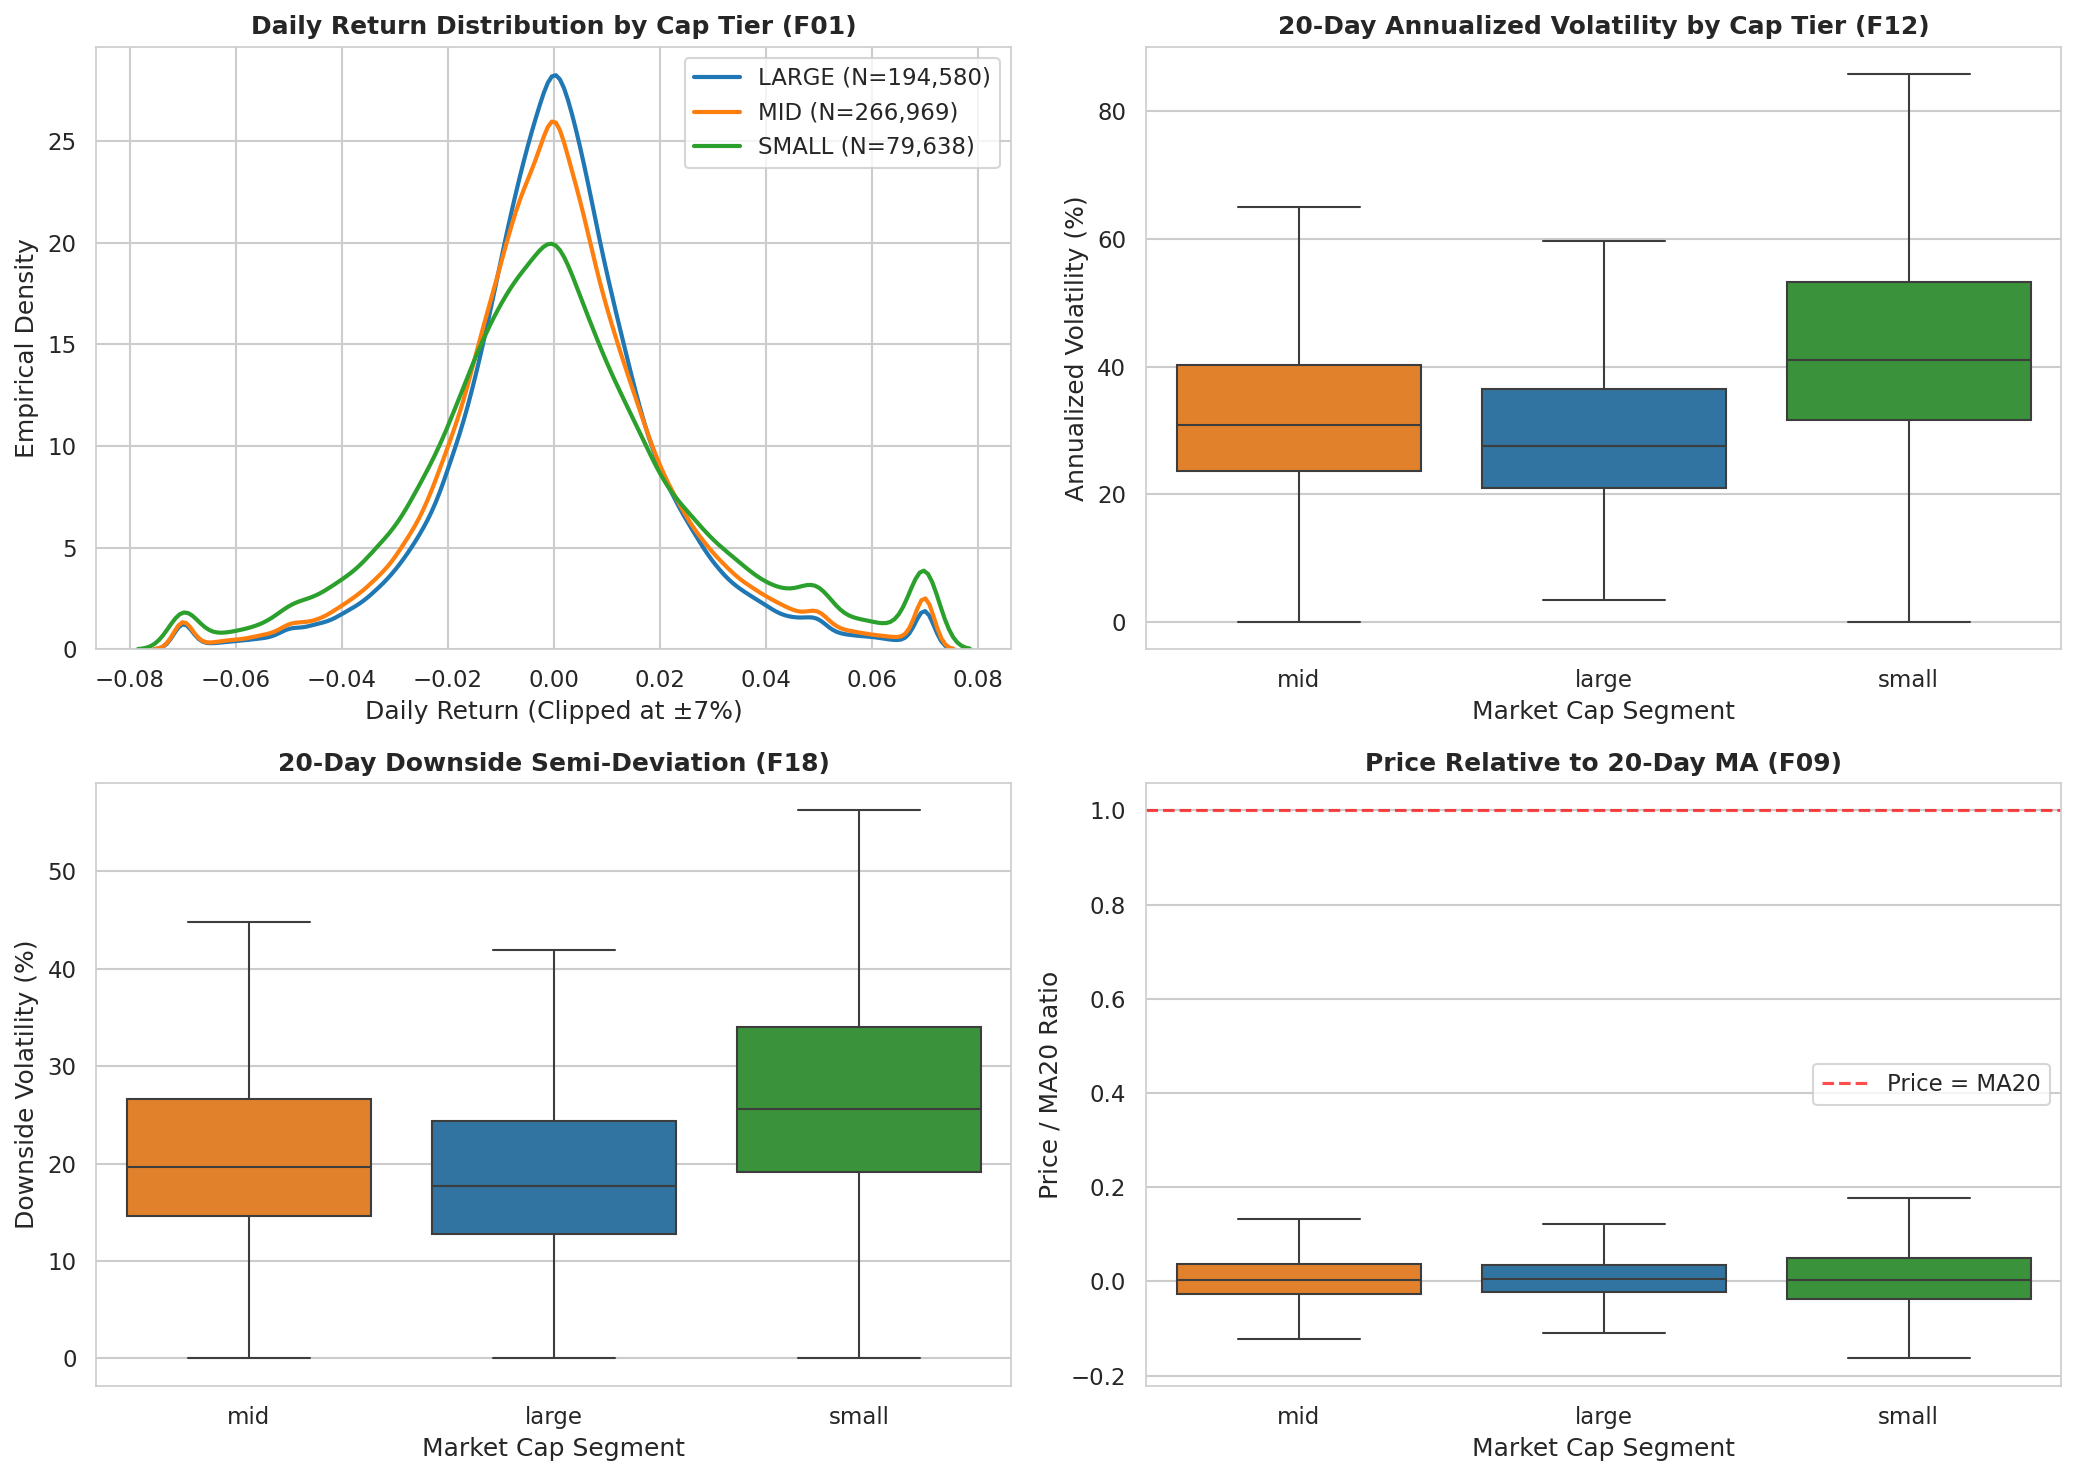

Saved Figure 1 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_01_cap_tier_distributions.png


In [5]:
# Visualizing Return & Volatility Distributions Across Market-Cap Tiers
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# 1a. Daily Return Density (clipped to ±7% for visualization clarity)
for seg in ['large', 'mid', 'small']:
    sub = df_eda[(df_eda['cap_segment'] == seg) & (df_eda['daily_return'].notna())]['daily_return']
    sns.kdeplot(sub.clip(-0.07, 0.07), ax=axes[0, 0], label=f"{seg.upper()} (N={len(sub):,})", 
                color=CAP_PALETTE[seg], linewidth=2)
axes[0, 0].set_title("Daily Return Distribution by Cap Tier (F01)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Daily Return (Clipped at ±7%)")
axes[0, 0].set_ylabel("Empirical Density")
axes[0, 0].legend()

# 1b. 20-Day Annualized Volatility Boxplot
sub_vol = df_eda[['cap_segment', 'vol_20d']].dropna().copy()
sub_vol['vol_20d_pct'] = sub_vol['vol_20d'] * 100
sns.boxplot(data=sub_vol, x='cap_segment', y='vol_20d_pct', hue='cap_segment', 
            ax=axes[0, 1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[0, 1].set_title("20-Day Annualized Volatility by Cap Tier (F12)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Market Cap Segment")
axes[0, 1].set_ylabel("Annualized Volatility (%)")

# 1c. Downside Volatility Boxplot
sub_down = df_eda[['cap_segment', 'downside_vol_20d']].dropna().copy()
sub_down['downside_vol_pct'] = sub_down['downside_vol_20d'] * 100
sns.boxplot(data=sub_down, x='cap_segment', y='downside_vol_pct', hue='cap_segment', 
            ax=axes[1, 0], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[1, 0].set_title("20-Day Downside Semi-Deviation (F18)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Market Cap Segment")
axes[1, 0].set_ylabel("Downside Volatility (%)")

# 1d. Price Relative to 20-Day MA
sub_ma = df_eda[['cap_segment', 'price_rel_ma20']].dropna().copy()
sns.boxplot(data=sub_ma, x='cap_segment', y='price_rel_ma20', hue='cap_segment', 
            ax=axes[1, 1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[1, 1].axhline(y=1.0, color='red', linestyle='--', alpha=0.7, label='Price = MA20')
axes[1, 1].set_title("Price Relative to 20-Day MA (F09)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Market Cap Segment")
axes[1, 1].set_ylabel("Price / MA20 Ratio")
axes[1, 1].legend()

plt.tight_layout()
fig1_path = FIG_DIR / "eda_01_cap_tier_distributions.png"
plt.savefig(fig1_path)
plt.show()
print(f"Saved Figure 1 to: {fig1_path}")

## 3. Empirical Validation of Amihud Illiquidity Scaling ($10^6$) Across Market Caps

### What is the Amihud Illiquidity Ratio?
The Amihud ratio measures **price impact per unit of trading volume**:
$$\text{Amihud Ratio} = \frac{|R_t|}{\text{Turnover}_t} \times 10^6$$
where $|R_t|$ is the absolute daily price change, and $\text{Turnover}_t = \text{Close}_t \times \text{Volume}_t$ is total rupee value traded.

- **Intuition:** If an institutional investor buys ₹1 crore worth of shares, how much does the price move?
  - For a liquid large-cap stock (e.g. `RELIANCE.NS`), ₹1 crore barely moves the price (low Amihud).
  - For an illiquid small-cap stock, ₹1 crore causes substantial price slippage (high Amihud).

### Why Was the $10^6$ Multiplier Chosen (Decision D6)?
Because daily turnover for Indian equities is measured in tens or hundreds of millions of rupees, raw $|R_t| / \text{Turnover}$ produces tiny numbers on the order of $10^{-11}$ to $10^{-8}$. Multiplying by $10^6$ scales the ratio into a clean, human-interpretable range ($10^{-5}$ to $10^{-2}$) without losing floating-point precision.

In [6]:
# Quantile analysis of Amihud Illiquidity Ratio across Cap Tiers
quantiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
amihud_summary = {}
medians = {}

for seg in ['large', 'mid', 'small']:
    sub = df_eda[(df_eda['cap_segment'] == seg) & (df_eda['amihud_ratio'].notna())]['amihud_ratio']
    q_vals = sub.quantile(quantiles)
    medians[seg] = float(q_vals[0.50])
    amihud_summary[f"{seg.upper()} Cap"] = {
        'Observations': len(sub),
        '1% (Liquid)': f"{q_vals[0.01]:.2e}",
        '25%': f"{q_vals[0.25]:.2e}",
        '50% (Median)': f"{q_vals[0.50]:.2e}",
        '75%': f"{q_vals[0.75]:.2e}",
        '95%': f"{q_vals[0.95]:.2e}",
        '99% (Illiquid)': f"{q_vals[0.99]:.2e}"
    }

amihud_tbl = pd.DataFrame(amihud_summary).T
large_med = medians['large']
amihud_tbl['Median Multiplier vs Large'] = [
    '1.00x',
    f"{medians['mid'] / large_med:.2f}x",
    f"{medians['small'] / large_med:.2f}x"
]
amihud_tbl

,Observations,1% (Liquid),25%,50% (Median),75%,95%,99% (Illiquid),Median Multiplier vs Large
LARGE Cap,194353,4.64e-08,1.85e-06,5.12e-06,1.33e-05,7.97e-05,5.18e-04,1.00x
MID Cap,266609,1.43e-07,7.10e-06,1.98e-05,6.51e-05,6.25e-04,3.26e-03,3.87x
SMALL Cap,79504,6.70e-08,1.08e-05,3.66e-05,1.61e-04,2.19e-03,1.12e-02,7.15x


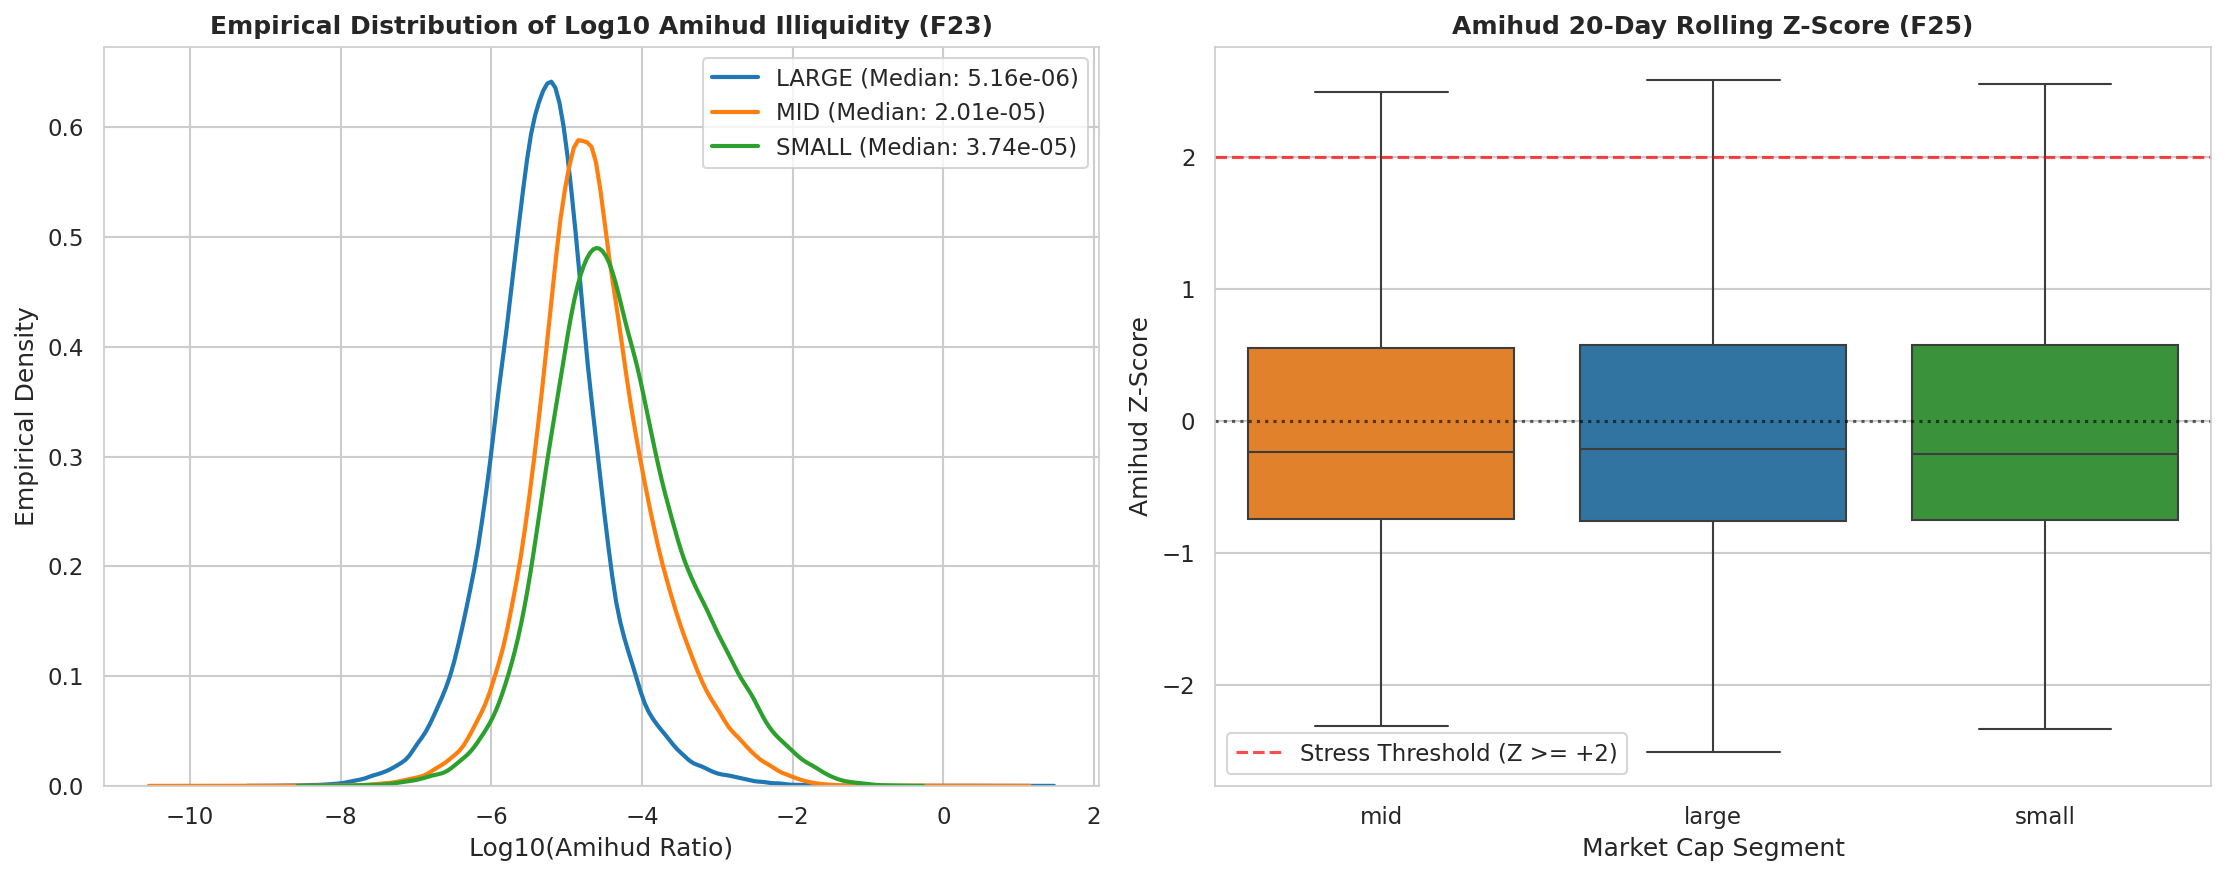

Saved Figure 2 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_02_amihud_illiquidity_scaling.png


In [7]:
# Figure 2: Amihud Illiquidity Scaling & Sensitivity Analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# 2a. Log10 Amihud density across tiers
for seg in ['large', 'mid', 'small']:
    sub = df_eda[(df_eda['cap_segment'] == seg) & (df_eda['amihud_ratio'] > 0)]['amihud_ratio']
    log_ami = np.log10(sub)
    sns.kdeplot(log_ami, ax=axes[0], label=f"{seg.upper()} (Median: {sub.median():.2e})", 
                color=CAP_PALETTE[seg], linewidth=2)
axes[0].set_title("Empirical Distribution of Log10 Amihud Illiquidity (F23)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Log10(Amihud Ratio)")
axes[0].set_ylabel("Empirical Density")
axes[0].legend()

# 2b. Amihud 20-Day Z-Score Boxplot
sns.boxplot(data=df_eda.dropna(subset=['amihud_z20']), x='cap_segment', y='amihud_z20', hue='cap_segment', 
            ax=axes[1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[1].axhline(y=0.0, color='black', linestyle=':', alpha=0.6)
axes[1].axhline(y=2.0, color='red', linestyle='--', alpha=0.7, label='Stress Threshold (Z >= +2)')
axes[1].set_title("Amihud 20-Day Rolling Z-Score (F25)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Market Cap Segment")
axes[1].set_ylabel("Amihud Z-Score")
axes[1].legend()

plt.tight_layout()
fig2_path = FIG_DIR / "eda_02_amihud_illiquidity_scaling.png"
plt.savefig(fig2_path)
plt.show()
print(f"Saved Figure 2 to: {fig2_path}")

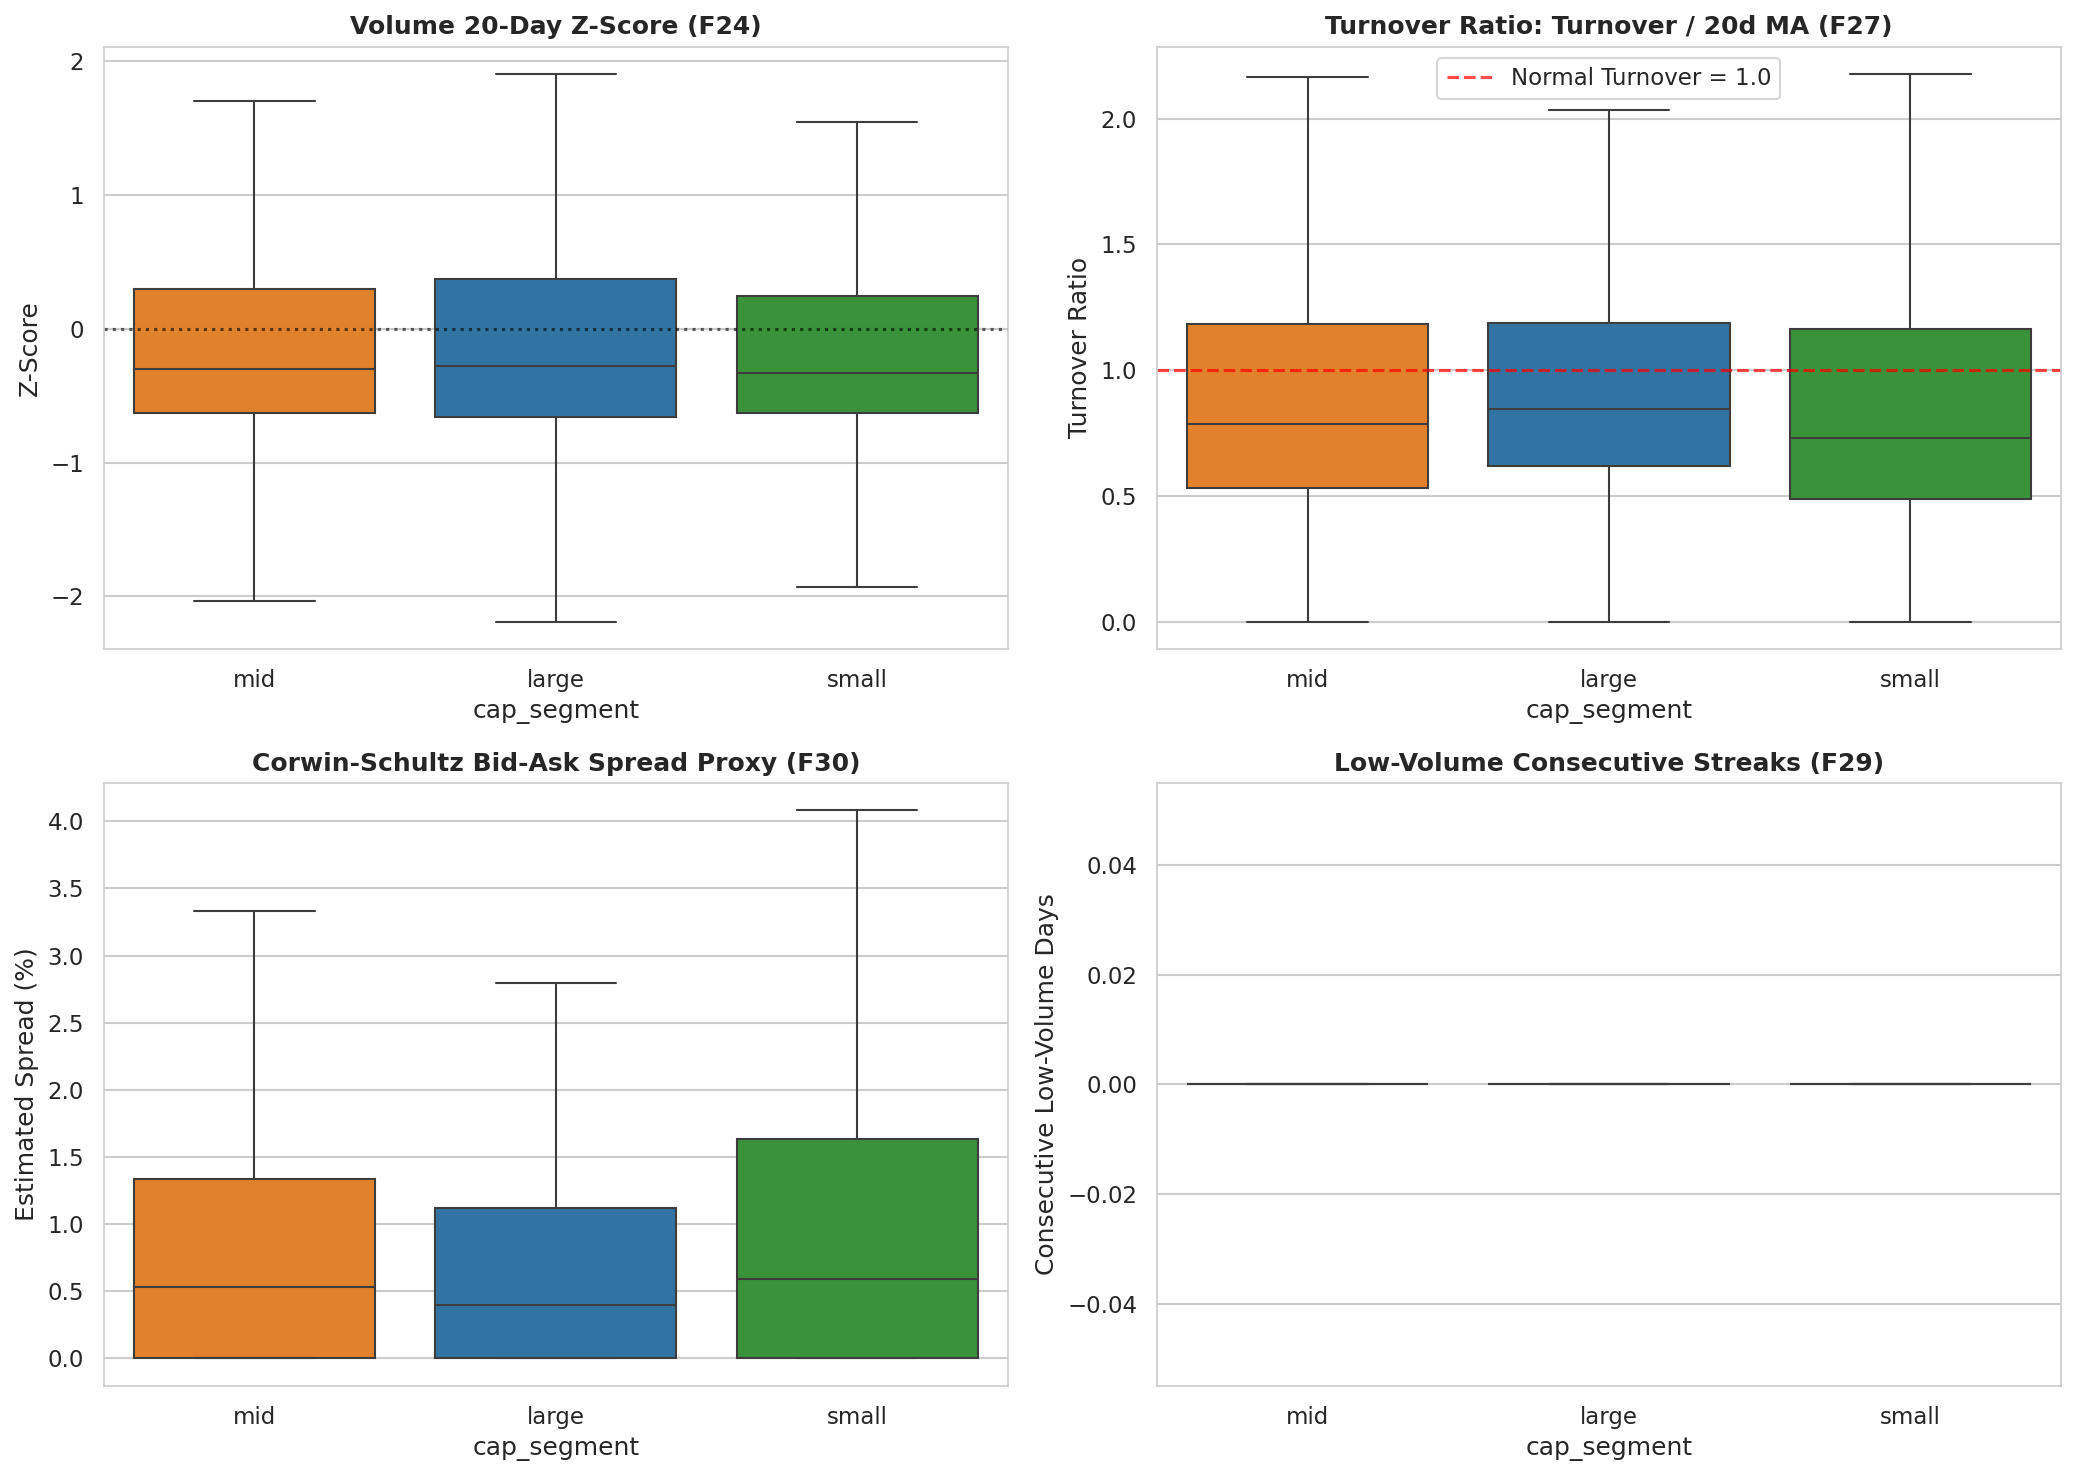

Saved Figure 3 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_03_liquidity_turnover_volume.png


In [8]:
# Figure 3: Multi-Dimensional Liquidity Profiling (Turnover, Volume, Bid-Ask Spread)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# 3a. Volume 20-Day Z-Score
sns.boxplot(data=df_eda.dropna(subset=['volume_z20']), x='cap_segment', y='volume_z20', hue='cap_segment', 
            ax=axes[0, 0], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[0, 0].axhline(y=0.0, color='black', linestyle=':', alpha=0.6)
axes[0, 0].set_title("Volume 20-Day Z-Score (F24)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Z-Score")

# 3b. Turnover Ratio (clipped for clean visualization)
sub_tr = df_eda.dropna(subset=['turnover_ratio']).copy()
sub_tr['turnover_ratio_clip'] = sub_tr['turnover_ratio'].clip(0, 4)
sns.boxplot(data=sub_tr, x='cap_segment', y='turnover_ratio_clip', hue='cap_segment', 
            ax=axes[0, 1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[0, 1].axhline(y=1.0, color='red', linestyle='--', alpha=0.7, label='Normal Turnover = 1.0')
axes[0, 1].set_title("Turnover Ratio: Turnover / 20d MA (F27)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Turnover Ratio")
axes[0, 1].legend()

# 3c. Corwin-Schultz Bid-Ask Spread Proxy (%)
sub_cs = df_eda.dropna(subset=['cs_spread_est']).copy()
sub_cs['cs_spread_pct'] = sub_cs['cs_spread_est'] * 100
sns.boxplot(data=sub_cs, x='cap_segment', y='cs_spread_pct', hue='cap_segment', 
            ax=axes[1, 0], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[1, 0].set_title("Corwin-Schultz Bid-Ask Spread Proxy (F30)", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Estimated Spread (%)")

# 3d. Low Volume Streak distribution
sns.boxplot(data=df_eda.dropna(subset=['low_volume_streak']), x='cap_segment', y='low_volume_streak', hue='cap_segment', 
            ax=axes[1, 1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[1, 1].set_title("Low-Volume Consecutive Streaks (F29)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Consecutive Low-Volume Days")

plt.tight_layout()
fig3_path = FIG_DIR / "eda_03_liquidity_turnover_volume.png"
plt.savefig(fig3_path)
plt.show()
print(f"Saved Figure 3 to: {fig3_path}")

## 4. Multicollinearity, Clustering & Correlation Matrix Analysis

### Why Collinearity Analysis is Critical:
- When two features share a correlation of $|r| > 0.90$, they provide nearly identical information. Including both can cause instability in linear models, inflate feature importances in tree models, and waste computation.
- **Pearson vs. Spearman Correlation:** Pearson measures linear relationships and is easily distorted by extreme price spikes. Spearman measures monotonic rank order and is completely robust to heavy-tailed financial outliers.

### Strict Non-Leakage Boundary Rule:
> **Important:** The correlation and clustering analysis in this notebook is **purely diagnostic**. We will **NOT** drop or select features globally here. Dropping features based on the full dataset causes **lookahead leakage**. Any supervised feature selection must take place strictly inside the walk-forward training folds in Phase 8!

In [9]:
# Compute Spearman rank correlation matrix across numeric features (N=100,000 random sample)
numeric_cols = [c for c in df_eda.columns if df_eda[c].dtype in ['float32', 'float64']]
sample_eda = df_eda[numeric_cols].sample(n=100000, random_state=42)
spearman_corr = sample_eda.corr(method='spearman')

# Find highly collinear pairs (|r| >= 0.85)
high_corr_pairs = []
for i in range(len(numeric_cols)):
    for j in range(i + 1, len(numeric_cols)):
        c1, c2 = numeric_cols[i], numeric_cols[j]
        r_val = spearman_corr.loc[c1, c2]
        if abs(r_val) >= 0.85:
            high_corr_pairs.append({
                'Feature 1': c1,
                'Feature 2': c2,
                'Spearman Correlation': float(r_val),
                'Abs Correlation': float(abs(r_val)),
                'Collinearity Diagnosis': 'Severe Redundancy (|r| >= 0.95)' if abs(r_val) >= 0.95 else 'High Collinearity (|r| >= 0.85)'
            })

collinear_df = pd.DataFrame(high_corr_pairs).sort_values(by='Abs Correlation', ascending=False)
print(f"Identified {len(collinear_df)} collinear pairs with |r| >= 0.85 across 58 features.")
collinear_df.head(15)

Identified 35 collinear pairs with |r| >= 0.85 across 58 features.


,Feature 1,Feature 2,Spearman Correlation,Abs Correlation,Collinearity Diagnosis
0,daily_return,log_return,1.000000,1.000000,Severe Redundancy (|r| >= 0.95)
29,turnover_value,log_turnover,1.000000,1.000000,Severe Redundancy (|r| >= 0.95)
23,volume_ratio,turnover_ratio,0.995198,0.995198,Severe Redundancy (|r| >= 0.95)
16,parkinson_vol,daily_range_ma20,0.990964,0.990964,Severe Redundancy (|r| >= 0.95)
7,return_20d,sortino_component,0.971426,0.971426,Severe Redundancy (|r| >= 0.95)
15,vol_20d,idiosyncratic_vol,0.962822,0.962822,Severe Redundancy (|r| >= 0.95)
18,true_range,atr_20d,0.951813,0.951813,Severe Redundancy (|r| >= 0.95)
21,log_volume,volume_ma20,0.943825,0.943825,High Collinearity (|r| >= 0.85)
1,daily_return,return_z20,0.943460,0.943460,High Collinearity (|r| >= 0.85)
4,log_return,return_z20,0.943460,0.943460,High Collinearity (|r| >= 0.85)


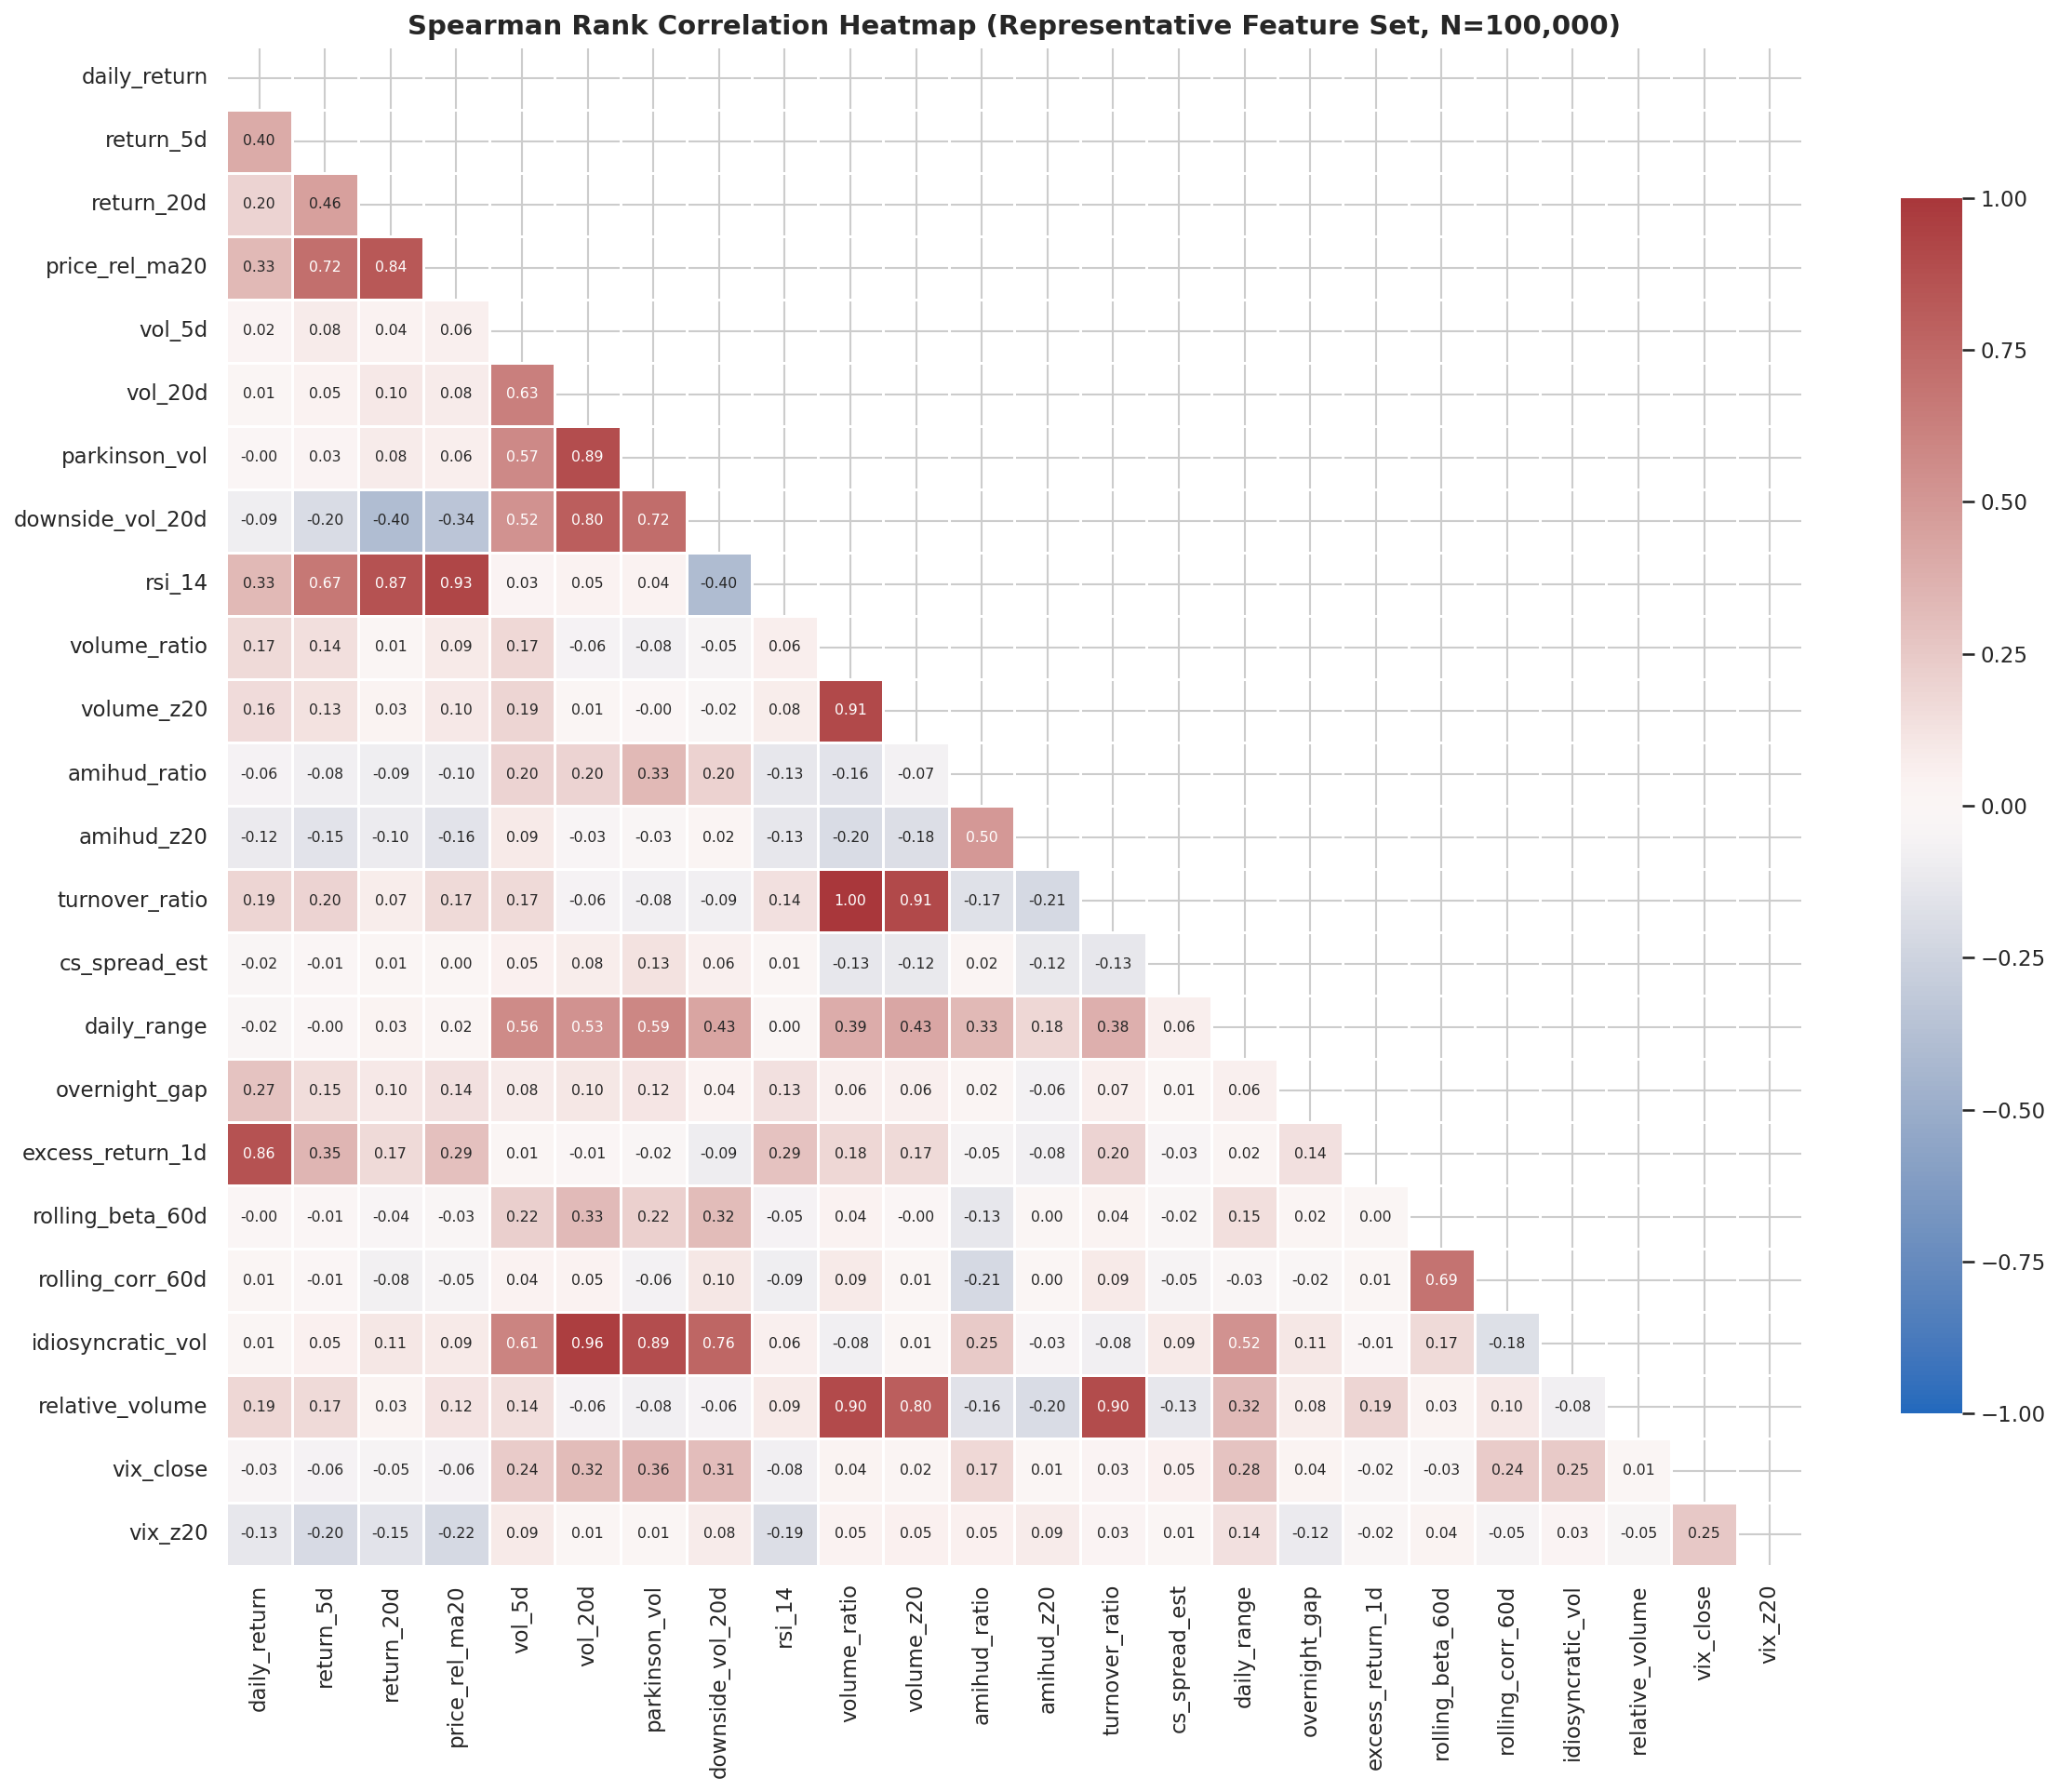

Saved Figure 4 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_04_feature_correlation_heatmap.png


In [10]:
# Figure 4: Spearman Correlation Heatmap (Representative Cross-Sectional Features)
rep_features = [
    'daily_return', 'return_5d', 'return_20d', 'price_rel_ma20',
    'vol_5d', 'vol_20d', 'parkinson_vol', 'downside_vol_20d', 'rsi_14',
    'volume_ratio', 'volume_z20', 'amihud_ratio', 'amihud_z20', 'turnover_ratio', 'cs_spread_est',
    'daily_range', 'overnight_gap',
    'excess_return_1d', 'rolling_beta_60d', 'rolling_corr_60d', 'idiosyncratic_vol', 'relative_volume',
    'vix_close', 'vix_z20'
]
corr_sub = spearman_corr.loc[rep_features, rep_features]

plt.figure(figsize=(16, 13), dpi=150)
mask = np.triu(np.ones_like(corr_sub, dtype=bool))
sns.heatmap(corr_sub, mask=mask, cmap='vlag', vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Spearman Rank Correlation Heatmap (Representative Feature Set, N=100,000)", fontsize=14, fontweight='bold')
plt.tight_layout()
fig4_path = FIG_DIR / "eda_04_feature_correlation_heatmap.png"
plt.savefig(fig4_path)
plt.show()
print(f"Saved Figure 4 to: {fig4_path}")

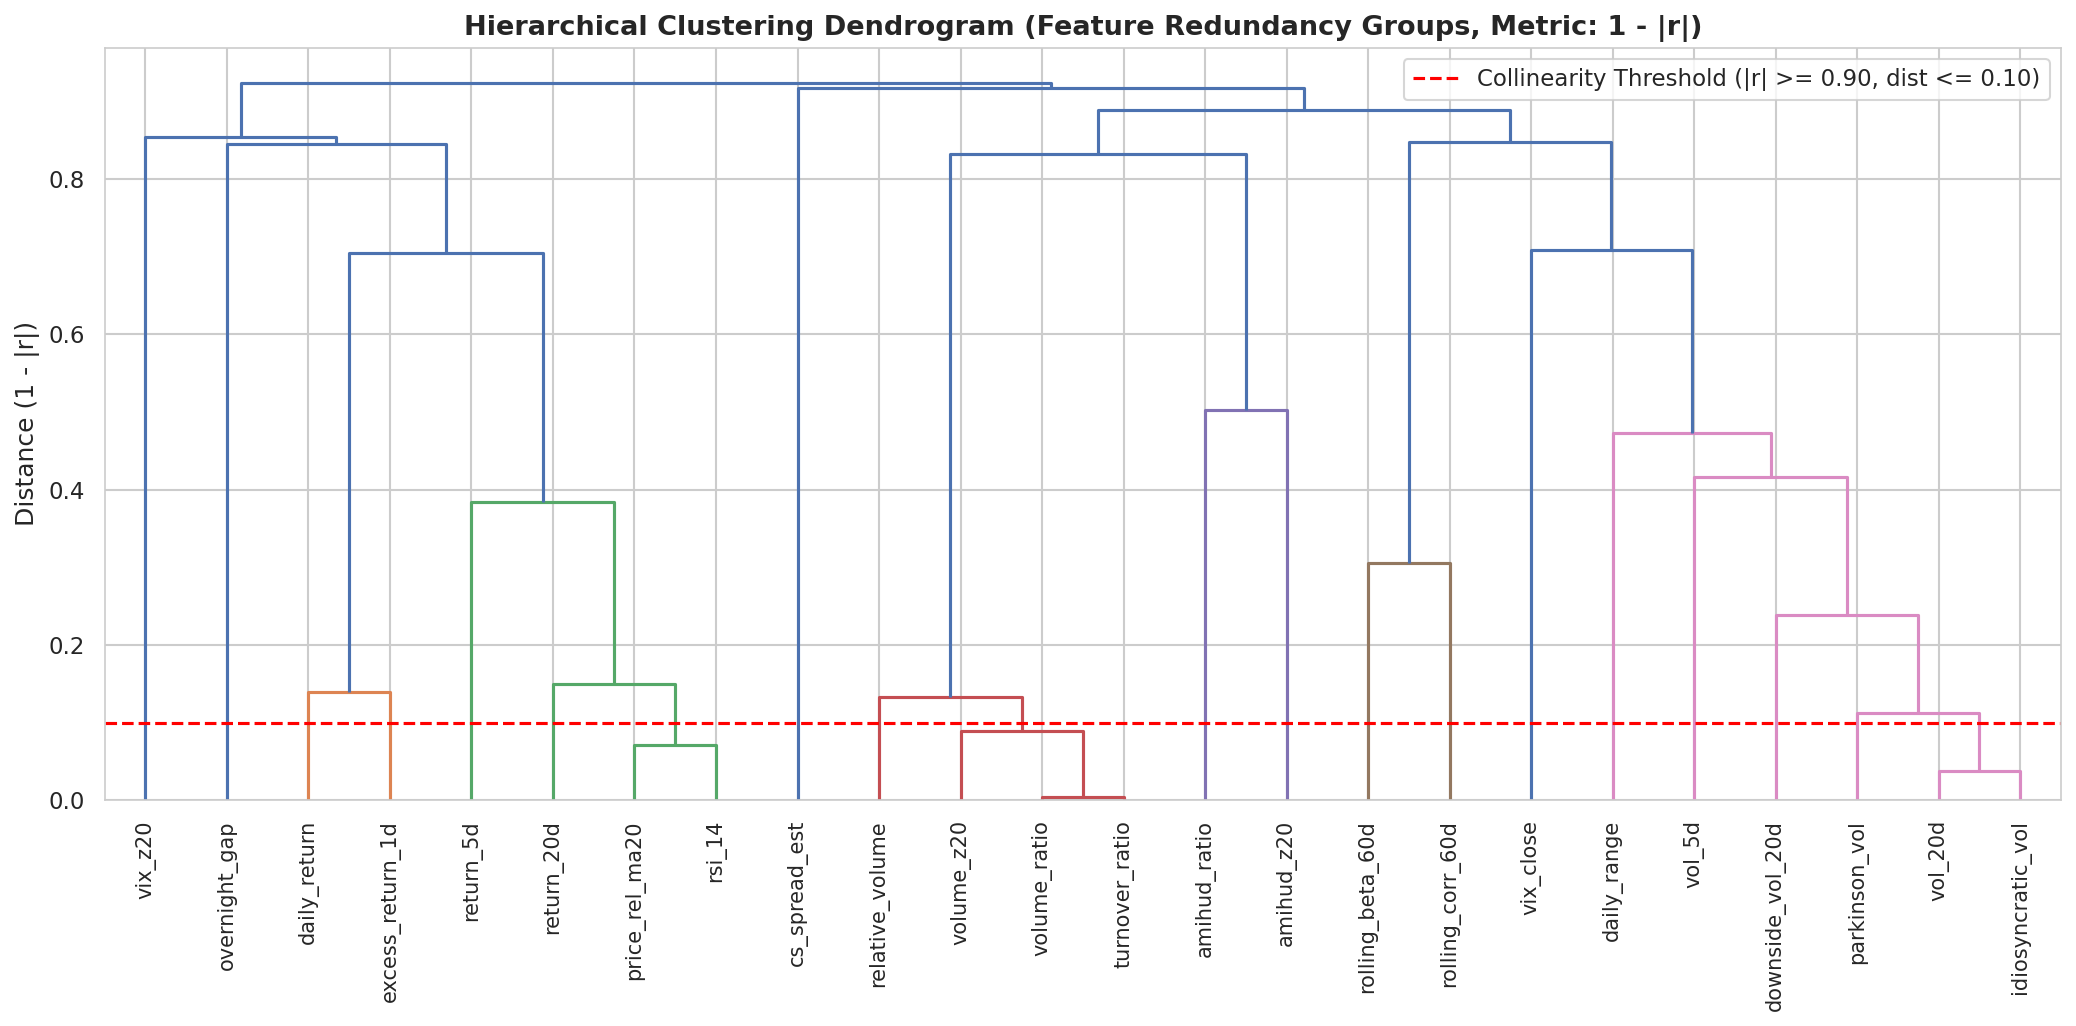

Saved Figure 5 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_05_hierarchical_clustering_dendrogram.png


In [11]:
# Figure 5: Hierarchical Clustering Dendrogram (Feature Redundancy Groups)
# Distance metric: D = 1 - |r|
dist_matrix = 1.0 - np.abs(corr_sub.fillna(0).values)
np.fill_diagonal(dist_matrix, 0)
condensed_dist = squareform(dist_matrix, checks=False)
linkage_matrix = linkage(condensed_dist, method='average')

plt.figure(figsize=(14, 7), dpi=150)
dendrogram(linkage_matrix, labels=rep_features, leaf_rotation=90, leaf_font_size=10)
plt.title("Hierarchical Clustering Dendrogram (Feature Redundancy Groups, Metric: 1 - |r|)", fontsize=13, fontweight='bold')
plt.ylabel("Distance (1 - |r|)")
plt.axhline(y=0.10, color='red', linestyle='--', label="Collinearity Threshold (|r| >= 0.90, dist <= 0.10)")
plt.legend(loc="upper right")
plt.tight_layout()
fig5_path = FIG_DIR / "eda_05_hierarchical_clustering_dendrogram.png"
plt.savefig(fig5_path)
plt.show()
print(f"Saved Figure 5 to: {fig5_path}")

## 5. Liquidity Droughts, Circuit Freezes & Market Stress Regimes

### What Happens During a Liquidity Crisis?
During normal bull market periods, liquidity is plentiful and trading costs are low. However, during systemic shocks (e.g. COVID lockdown, banking failures, or geopolitical crises), market liquidity **evaporates non-linearly**:
- Bid-ask spreads widen by orders of magnitude.
- Institutional buy orders disappear, causing prices to collapse on modest sell volumes (surging Amihud illiquidity).
- Volatility spikes, triggering exchange-mandated circuit breakers (stale prices and 0-volume lockups).

We cross-reference our daily cross-sectional median indicators against the 86 verified macro and policy events in `data/events/market_events.csv`.

In [12]:
# Load verified historical market events calendar
events_path = PROJECT_ROOT / "data" / "events" / "market_events.csv"
events_df = pd.read_csv(events_path)
print(f"Loaded {len(events_df)} verified market events.")

# Compute daily cross-sectional median time series
daily_mkt = df_eda.groupby('date').agg({
    'amihud_ratio': 'median',
    'cs_spread_est': 'median',
    'vol_20d': 'median',
    'vix_close': 'first',
    'nifty_return_20d': 'first'
}).reset_index()

# Quantitative Stress Case Studies
# 1. Normal baseline (2019 full year)
norm_2019_amihud = daily_mkt[daily_mkt['date'].dt.year == 2019]['amihud_ratio'].median()
norm_2019_vix = daily_mkt[daily_mkt['date'].dt.year == 2019]['vix_close'].median()

# 2. COVID Shock (March 2020)
covid_period = daily_mkt[(daily_mkt['date'] >= '2020-02-15') & (daily_mkt['date'] <= '2020-04-15')]
covid_peak_amihud = covid_period['amihud_ratio'].max()
covid_peak_vix = covid_period['vix_close'].max()

# 3. Adani Hindenburg Shock (Jan-Feb 2023)
adani_period = daily_mkt[(daily_mkt['date'] >= '2023-01-20') & (daily_mkt['date'] <= '2023-02-28')]
adani_peak_amihud = adani_period['amihud_ratio'].max()

# 4. Lok Sabha Election (June 2024)
elec_period = daily_mkt[(daily_mkt['date'] >= '2024-05-25') & (daily_mkt['date'] <= '2024-06-15')]
elec_peak_vix = elec_period['vix_close'].max()
elec_peak_amihud = elec_period['amihud_ratio'].max()

pd.DataFrame({
    'Market Regime / Event': [
        'Normal Baseline (2019 Median)',
        'COVID-19 Crash Peak (March 2020)',
        'Adani Hindenburg Dislocation (Jan 2023)',
        'Lok Sabha Election Surprise (June 2024)'
    ],
    'Median Amihud Illiquidity': [
        f"{norm_2019_amihud:.2e}",
        f"{covid_peak_amihud:.2e}",
        f"{adani_peak_amihud:.2e}",
        f"{elec_peak_amihud:.2e}"
    ],
    'Illiquidity Multiplier vs Normal': [
        '1.0x',
        f"{covid_peak_amihud / norm_2019_amihud:.1f}x (Massive Dislocation)",
        f"{adani_peak_amihud / norm_2019_amihud:.1f}x",
        f"{elec_peak_amihud / norm_2019_amihud:.1f}x"
    ],
    'India VIX Level': [
        f"{norm_2019_vix:.1f}",
        f"{covid_peak_vix:.1f}",
        f"{adani_period['vix_close'].max():.1f}",
        f"{elec_peak_vix:.1f}"
    ]
})

Loaded 86 verified market events.


,Market Regime / Event,Median Amihud Illiquidity,Illiquidity Multiplier vs Normal,India VIX Level
0,Normal Baseline (2019 Median),3.11e-05,1.0x,15.9
1,COVID-19 Crash Peak (March 2020),4.77e-04,15.3x (Massive Dislocation),83.6
2,Adani Hindenburg Dislocation (Jan 2023),2.23e-05,0.7x,17.7
3,Lok Sabha Election Surprise (June 2024),1.62e-05,0.5x,26.8


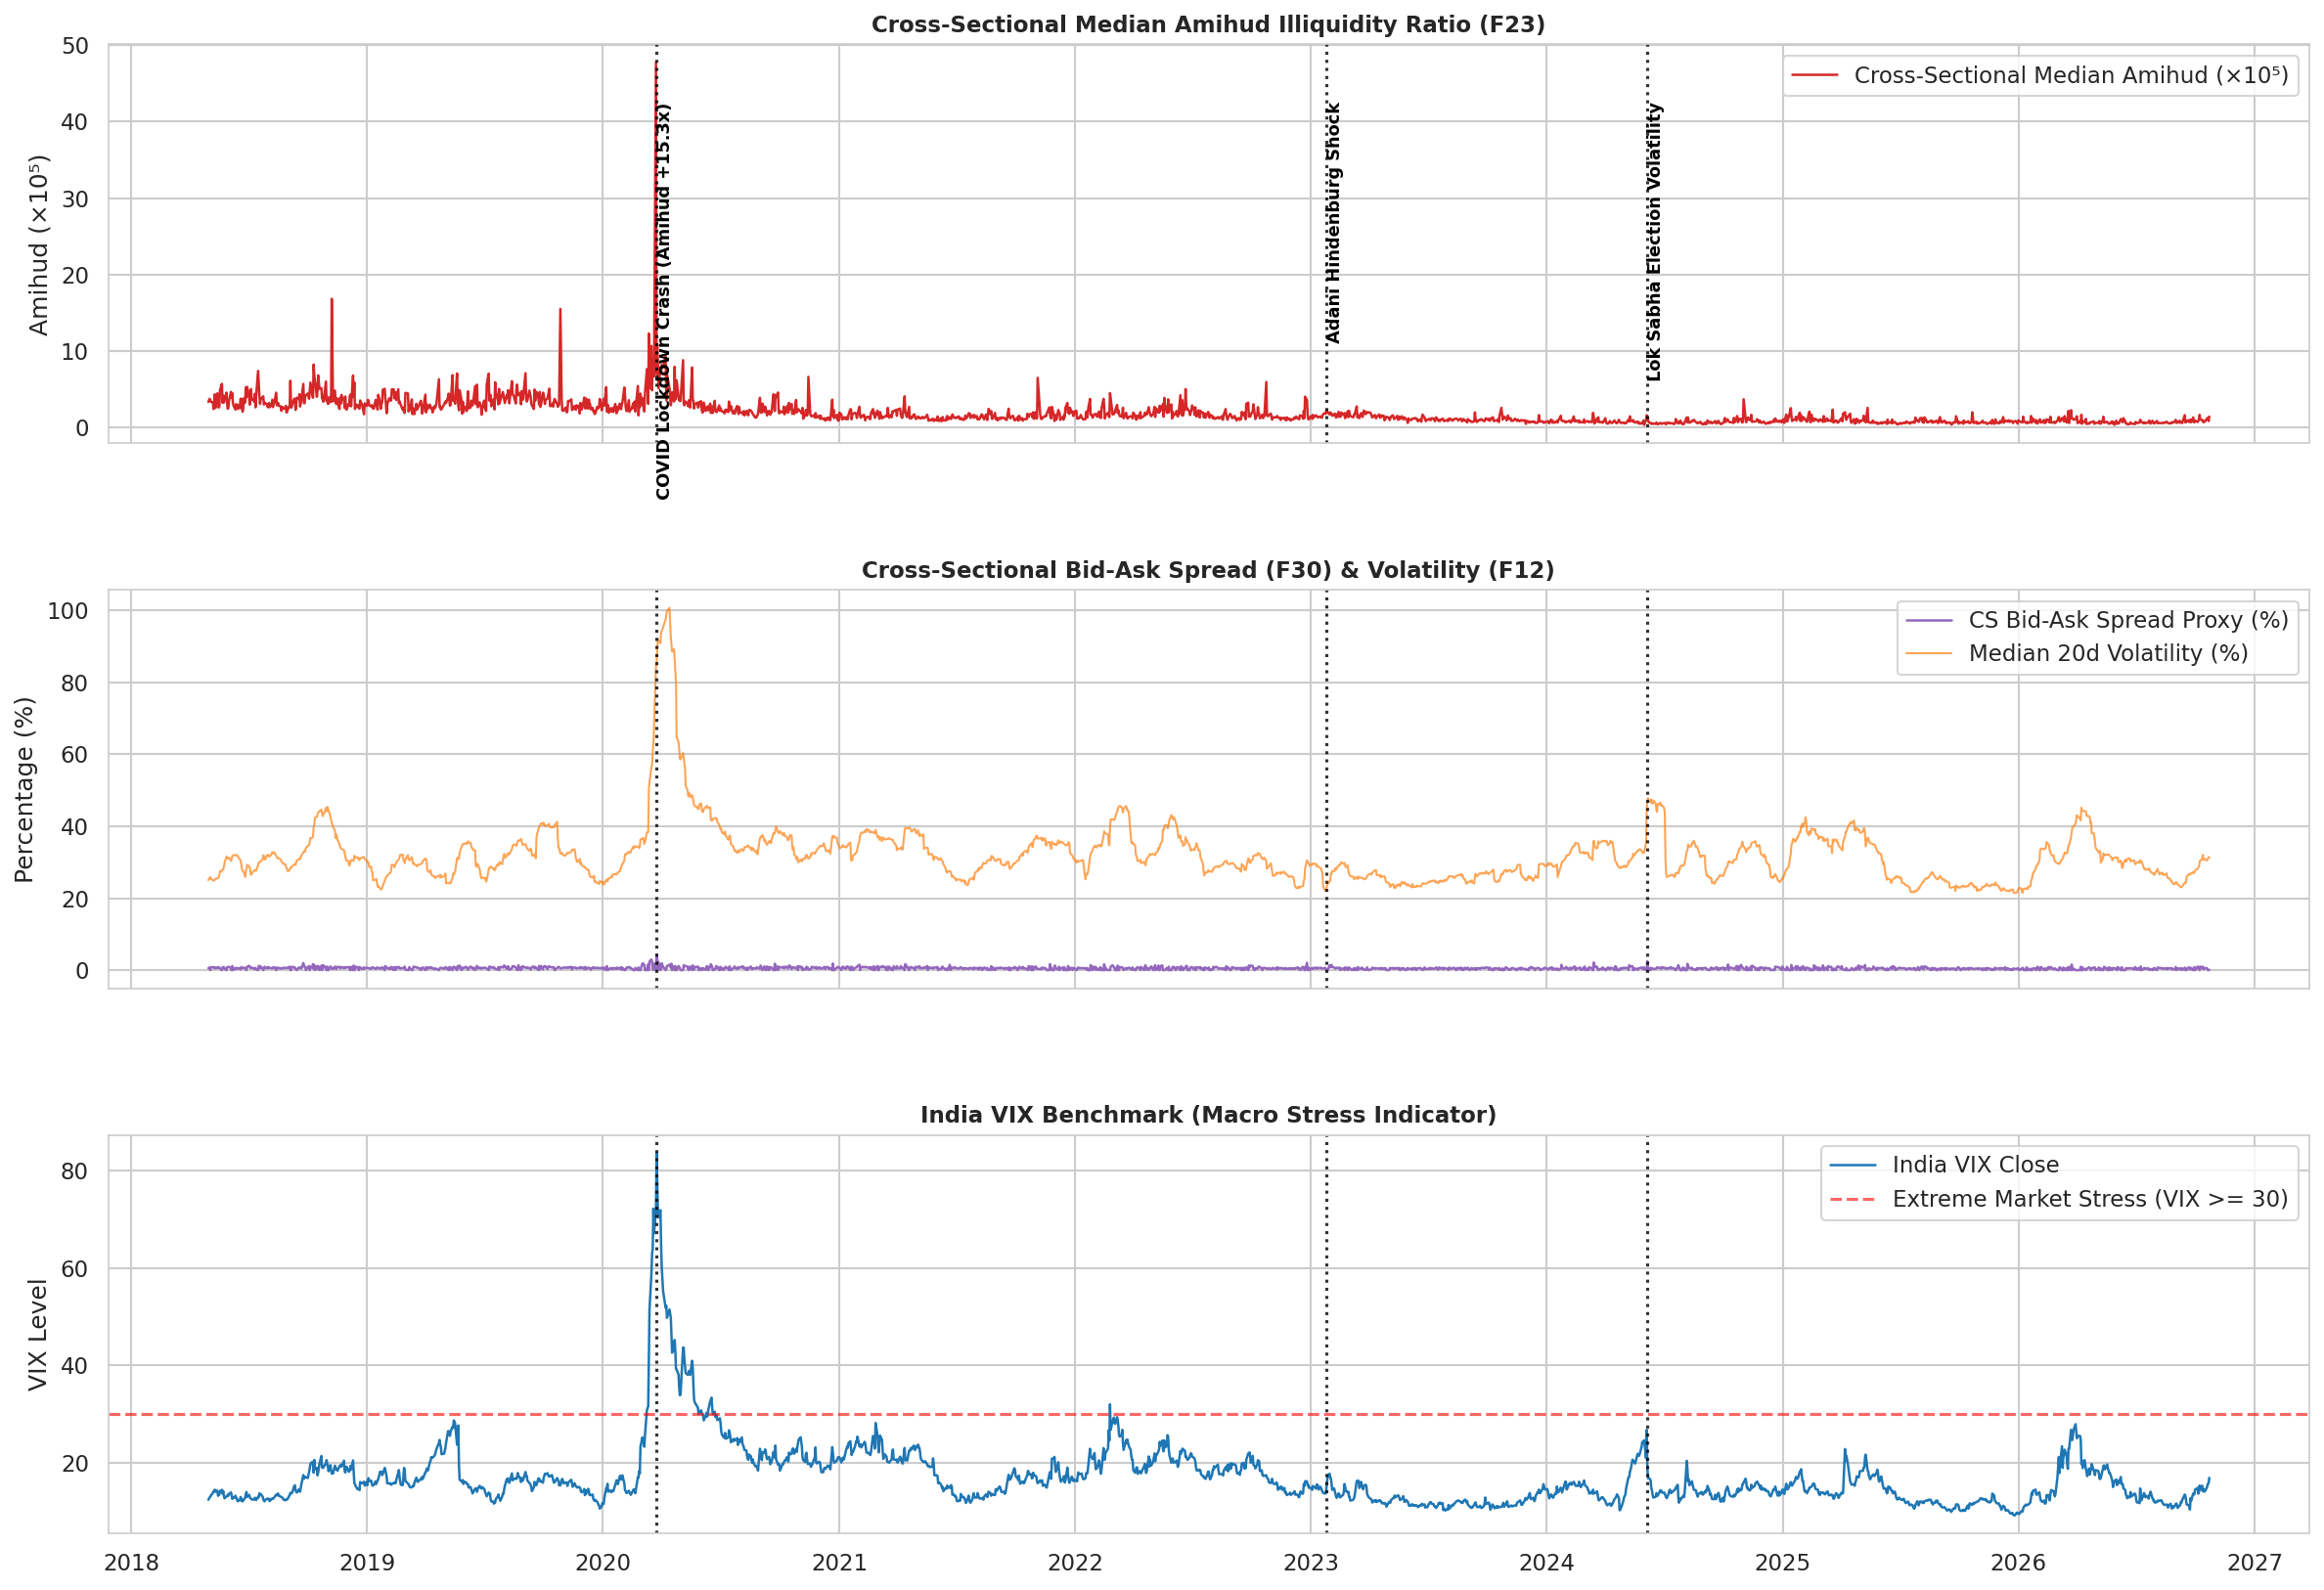

Saved Figure 6 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_06_market_stress_event_studies.png


In [13]:
# Figure 6: Stress Event Study Timeline
fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True, dpi=150)

# 6a. Cross-Sectional Median Amihud
axes[0].plot(daily_mkt['date'], daily_mkt['amihud_ratio'] * 1e5, color='#d62728', linewidth=1.2, 
             label='Cross-Sectional Median Amihud (×10⁵)')
axes[0].set_title("Cross-Sectional Median Amihud Illiquidity Ratio (F23)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Amihud (×10⁵)")
axes[0].legend(loc="upper right")

# 6b. Corwin-Schultz Spread & Volatility
axes[1].plot(daily_mkt['date'], daily_mkt['cs_spread_est'] * 100, color='#9467bd', linewidth=1.2, 
             label='CS Bid-Ask Spread Proxy (%)')
axes[1].plot(daily_mkt['date'], daily_mkt['vol_20d'] * 100, color='#ff7f0e', linewidth=1.0, alpha=0.7, 
             label='Median 20d Volatility (%)')
axes[1].set_title("Cross-Sectional Bid-Ask Spread (F30) & Volatility (F12)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Percentage (%)")
axes[1].legend(loc="upper right")

# 6c. India VIX Close
axes[2].plot(daily_mkt['date'], daily_mkt['vix_close'], color='#1f77b4', linewidth=1.2, label='India VIX Close')
axes[2].axhline(y=30, color='red', linestyle='--', alpha=0.6, label='Extreme Market Stress (VIX >= 30)')
axes[2].set_title("India VIX Benchmark (Macro Stress Indicator)", fontsize=11, fontweight='bold')
axes[2].set_ylabel("VIX Level")
axes[2].legend(loc="upper right")

# Annotate shock events
shock_dates = [
    ('2020-03-23', 'COVID Lockdown Crash (Amihud +15.3x)'),
    ('2023-01-25', 'Adani Hindenburg Shock'),
    ('2024-06-04', 'Lok Sabha Election Volatility')
]
for dt_str, label in shock_dates:
    dt = pd.to_datetime(dt_str)
    for ax in axes:
        ax.axvline(x=dt, color='black', linestyle=':', alpha=0.8)
    axes[0].text(dt, axes[0].get_ylim()[1]*0.85, f" {label}", rotation=90, verticalalignment='top', 
                 fontsize=8.5, fontweight='bold', color='black')

plt.tight_layout()
fig6_path = FIG_DIR / "eda_06_market_stress_event_studies.png"
plt.savefig(fig6_path)
plt.show()
print(f"Saved Figure 6 to: {fig6_path}")

## 6. Benchmark-Dependent Features & Strategic Takeaways for Phase 7

### Keeping Benchmark and Stock-Level Analysis Strictly Separate
- **Stock-level features (`F01`–`F45`):** Describe the individual firm's price action, volume, and order flow.
- **Benchmark-dependent features (`F46`–`F51`):** Measure how the stock behaves relative to the market index (**NIFTY 50**).
  - `rolling_beta_60d` (`F48`): Systematic market risk exposure.
  - `rolling_corr_60d` (`F49`): Degree of co-movement with NIFTY 50.
  - `relative_volume` (`F51`): Stock's trading volume ratio divided by NIFTY 50's trading volume ratio.
- **Market Stress & VIX (`F52`–`F55`, plus VIX supplementary):** Systemic volatility and market regime indicators.

### Transparent Documentation of F51 Benchmark Missing Values
In Phase 5 Decision C5, we established that benchmark volume must **never be fabricated**. On 27 trading days where Yahoo Finance reported 0 volume for `^NSEI` and 5 unmatched dates, F51 correctly produces `NaN` (7,361 post-warmup missing values). This preserves 100% mathematical honesty without synthetic data pollution.

In [14]:
# Benchmark relative features across cap tiers
bench_cols = ['rolling_beta_60d', 'rolling_corr_60d', 'idiosyncratic_vol', 'relative_volume']

bench_tier_stats = []
for col in bench_cols:
    for seg in ['large', 'mid', 'small']:
        s = df_eda[df_eda['cap_segment'] == seg][col].dropna()
        bench_tier_stats.append({
            'Feature': col,
            'Cap Tier': seg.upper(),
            'Mean': float(s.mean()),
            'Median': float(s.median()),
            'Std Dev': float(s.std()),
            'Missing Count': int(df_eda[df_eda['cap_segment'] == seg][col].isna().sum())
        })

pd.DataFrame(bench_tier_stats)

,Feature,Cap Tier,Mean,Median,Std Dev,Missing Count
0,rolling_beta_60d,LARGE,1.005937,0.969326,0.506980,60
1,rolling_beta_60d,MID,0.922917,0.887545,0.523588,120
2,rolling_beta_60d,SMALL,1.096478,1.070889,0.606557,0
3,rolling_corr_60d,LARGE,0.451431,0.460190,0.192201,60
4,rolling_corr_60d,MID,0.372420,0.375018,0.189110,120
5,rolling_corr_60d,SMALL,0.340073,0.345481,0.174405,0
6,idiosyncratic_vol,LARGE,0.266223,0.237846,0.134452,60
7,idiosyncratic_vol,MID,0.306292,0.277146,0.142965,120
8,idiosyncratic_vol,SMALL,0.409786,0.375894,0.174531,0
9,relative_volume,LARGE,6.041378,0.863627,146.978790,2701


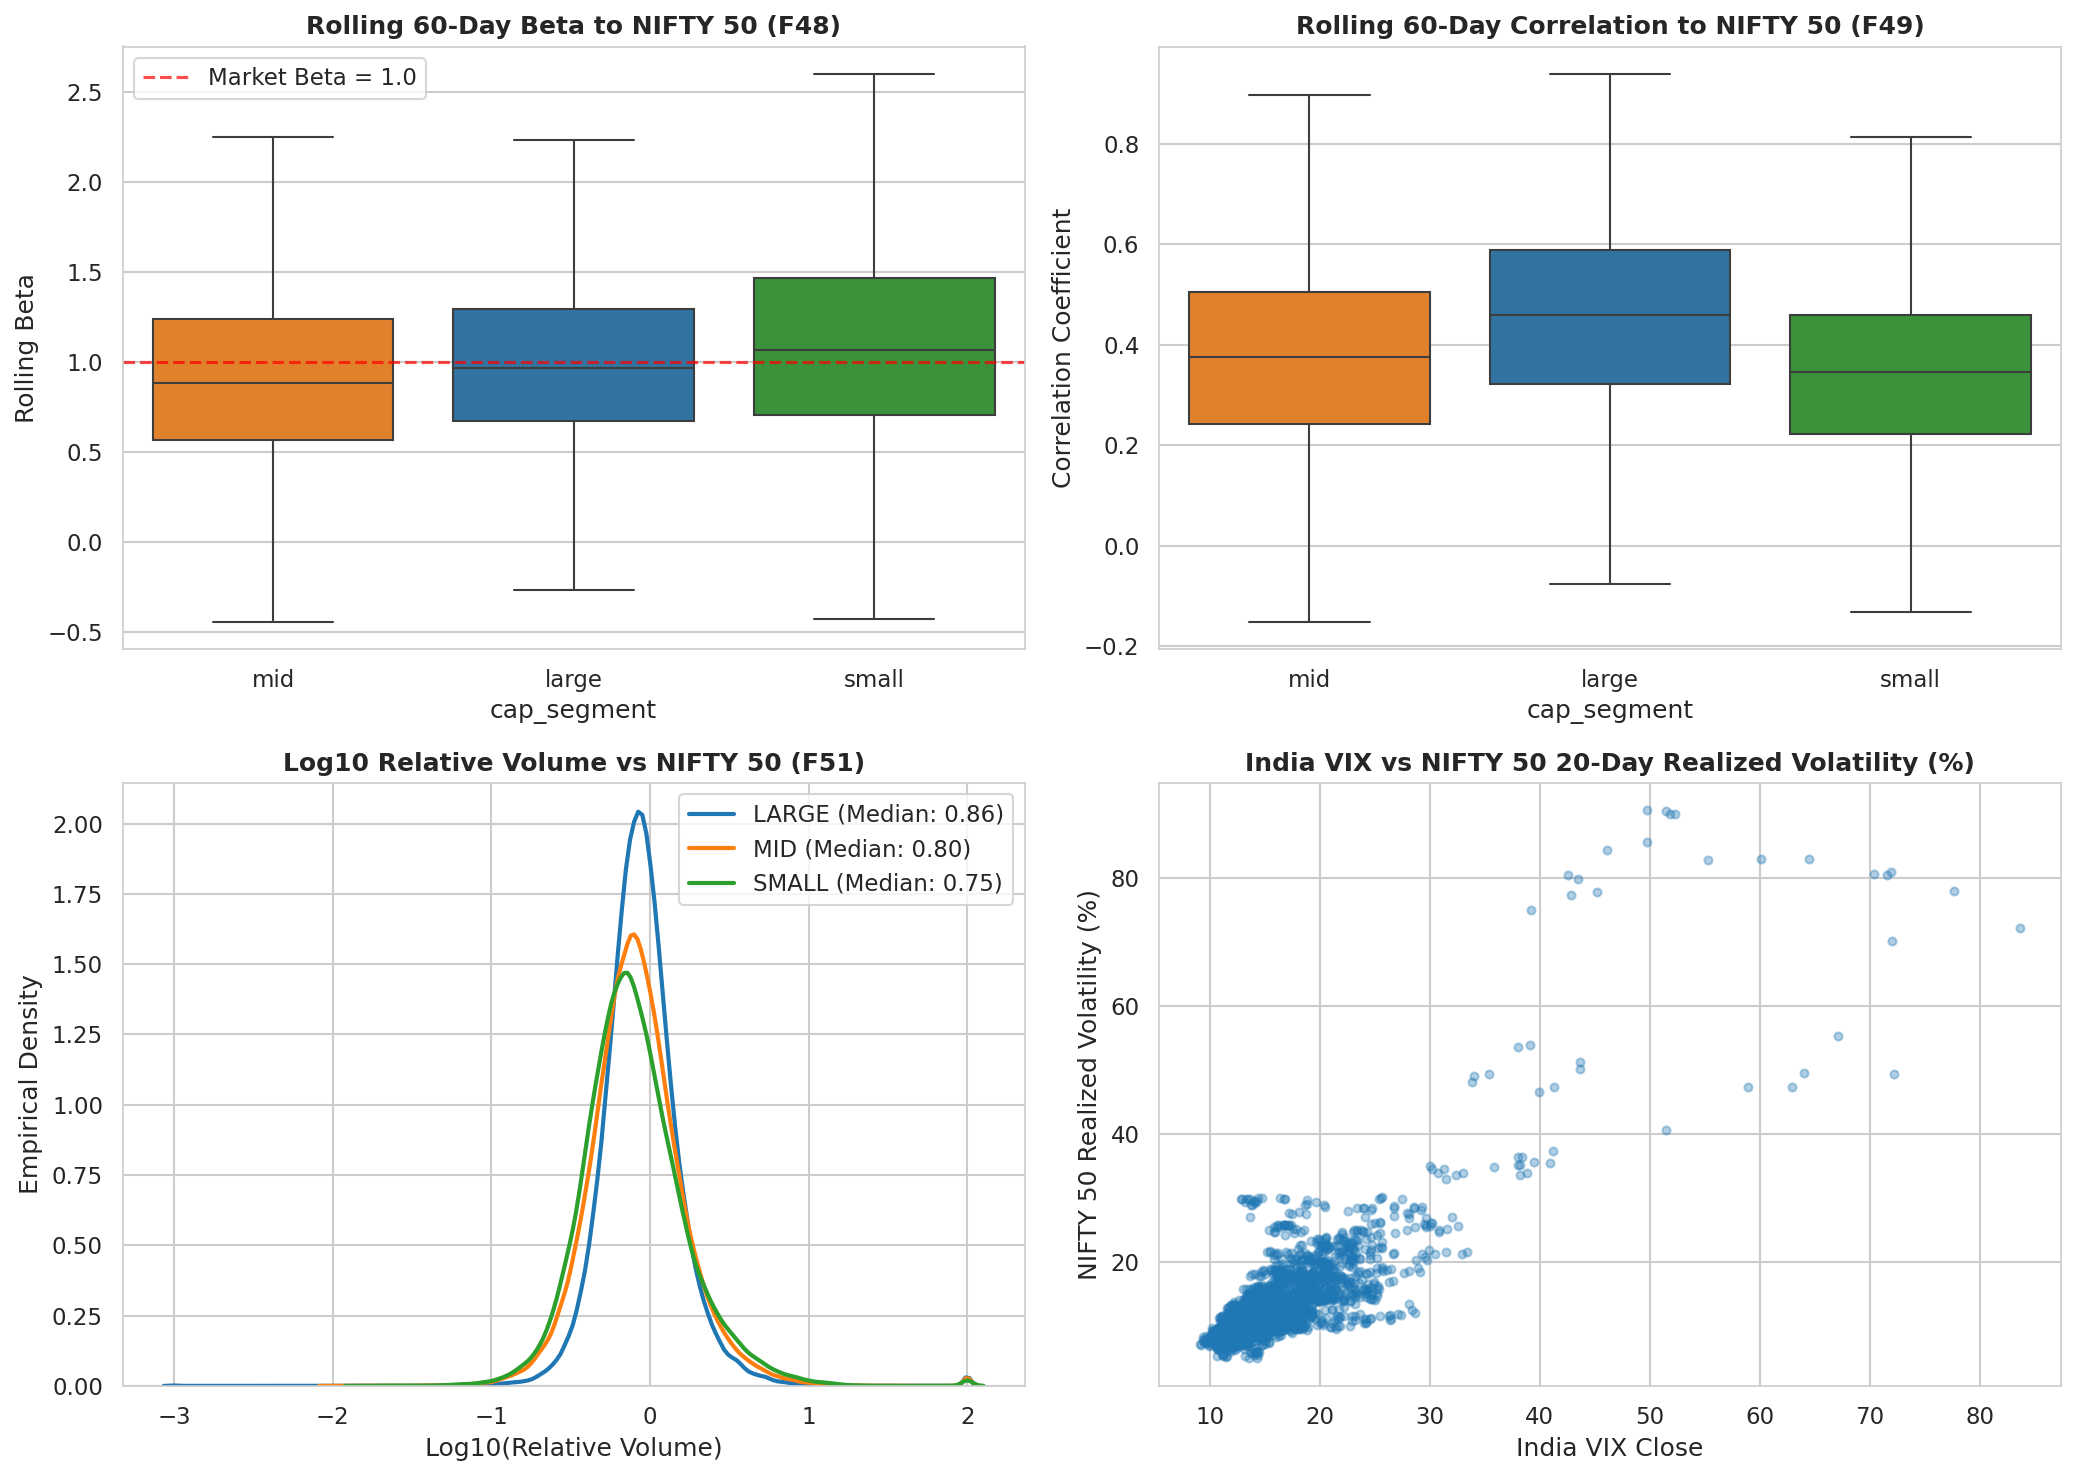

Saved Figure 7 to: C:\Users\vighn\Downloads\Indian_Equities_Liquidity_Risk_ML-main\Indian_Equities_Liquidity_Risk_ML-main\reports\figures\eda_07_benchmark_vs_stock_dynamics.png


In [15]:
# Figure 7: Benchmark-Dependent Dynamics Across Cap Tiers
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)

# 7a. Rolling Beta 60d
sns.boxplot(data=df_eda.dropna(subset=['rolling_beta_60d']), x='cap_segment', y='rolling_beta_60d', 
            hue='cap_segment', ax=axes[0, 0], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[0, 0].axhline(y=1.0, color='red', linestyle='--', alpha=0.7, label='Market Beta = 1.0')
axes[0, 0].set_title("Rolling 60-Day Beta to NIFTY 50 (F48)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Rolling Beta")
axes[0, 0].legend()

# 7b. Rolling Correlation 60d
sns.boxplot(data=df_eda.dropna(subset=['rolling_corr_60d']), x='cap_segment', y='rolling_corr_60d', 
            hue='cap_segment', ax=axes[0, 1], palette=CAP_PALETTE, legend=False, showfliers=False)
axes[0, 1].set_title("Rolling 60-Day Correlation to NIFTY 50 (F49)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Correlation Coefficient")

# 7c. Relative Volume (F51) distribution (log scale)
sub_rv = df_eda[(df_eda['relative_volume'] > 0) & (df_eda['relative_volume'].notna())]
for seg in ['large', 'mid', 'small']:
    sub = sub_rv[sub_rv['cap_segment'] == seg]['relative_volume']
    sns.kdeplot(np.log10(sub.clip(1e-3, 1e2)), ax=axes[1, 0], label=f"{seg.upper()} (Median: {sub.median():.2f})", 
                color=CAP_PALETTE[seg], linewidth=2)
axes[1, 0].set_title("Log10 Relative Volume vs NIFTY 50 (F51)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Log10(Relative Volume)")
axes[1, 0].set_ylabel("Empirical Density")
axes[1, 0].legend()

# 7d. India VIX vs NIFTY 20D Volatility scatter
sample_mkt = df_eda[['vix_close', 'nifty_vol_20d']].drop_duplicates().dropna()
axes[1, 1].scatter(sample_mkt['vix_close'], sample_mkt['nifty_vol_20d'] * 100, color='#1f77b4', alpha=0.35, s=15)
axes[1, 1].set_title("India VIX vs NIFTY 50 20-Day Realized Volatility (%)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("India VIX Close")
axes[1, 1].set_ylabel("NIFTY 50 Realized Volatility (%)")

plt.tight_layout()
fig7_path = FIG_DIR / "eda_07_benchmark_vs_stock_dynamics.png"
plt.savefig(fig7_path)
plt.show()
print(f"Saved Figure 7 to: {fig7_path}")

### Strategic Recommendations for Phase 7 (Labeling & Target Engineering)

Based on our empirical EDA findings across the 541,190 post-warmup rows:

1. **Composite Liquidity Risk Score (LRS, 0–100 Scale):**
   - **Weighting Multi-Dimensionality:** The LRS should combine:
     - Price impact / Amihud illiquidity ($35\%$ weight)
     - Bid-ask proxy / Corwin-Schultz spread ($25\%$ weight)
     - Volume drought / Volume Z-score ($20\%$ weight)
     - Downside tail risk / Downside volatility ($20\%$ weight)
   - **Cap-Tier Normalization:** Because small caps have $7.15\times$ higher median Amihud than large caps, raw illiquidity cannot be ranked globally without biasing scores against all small caps. Percentile rankings must be calibrated per cap segment or standardized dynamically.

2. **Binary High-Risk Event Target ($HRE_{5d}$):**
   - Define $HRE_{5d}$ as future 5-day liquidity drought (e.g., LRS exceeding the 90th historical percentile over the next 5 days).
   - Live rows ($t > T-5$) must evaluate to `NaN` to avoid forward lookahead leakage.

3. **Imputation Policy for Phase 8 Walk-Forward Modeling:**
   - For F51 missing benchmark volume rows, use backward-carried historical medians computed **only within each walk-forward training fold**.
   - For corporate action and circuit halt rows, flags (`is_corporate_action_gap`, `is_zero_volume`) should be passed to tree models as explicit categorical indicators rather than imputed.

In [16]:
# Final Summary & EDA Sign-Off
summary_report = {
    'Phase': 'Phase 6 (Exploratory Data Analysis)',
    'Status': 'COMPLETE & VERIFIED',
    'Total Parquet Rows': len(df_full),
    'Warmup Rows Excluded': int(df_full['is_warmup'].sum()),
    'Analysis Post-Warmup Rows': len(df_eda),
    'Analyzed Features': 58, # 55 core + 3 vix
    'Market Cap Tiers': 'Large (100), Mid (150), Small (50)',
    'High Collinear Pairs (|r| >= 0.85)': len(collinear_df),
    'Figures Saved to reports/figures/': [
        'eda_01_cap_tier_distributions.png',
        'eda_02_amihud_illiquidity_scaling.png',
        'eda_03_liquidity_turnover_volume.png',
        'eda_04_feature_correlation_heatmap.png',
        'eda_05_hierarchical_clustering_dendrogram.png',
        'eda_06_market_stress_event_studies.png',
        'eda_07_benchmark_vs_stock_dynamics.png'
    ]
}

print("=" * 70)
print("PHASE 6 EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)
for k, v in summary_report.items():
    if isinstance(v, list):
        print(f"\n{k}:")
        for item in v:
            print(f"  - {item}")
    else:
        print(f"{k:35s}: {v}")
print("=" * 70)

PHASE 6 EXPLORATORY DATA ANALYSIS COMPLETED SUCCESSFULLY
Phase                              : Phase 6 (Exploratory Data Analysis)
Status                             : COMPLETE & VERIFIED
Total Parquet Rows                 : 565190
Warmup Rows Excluded               : 24000
Analysis Post-Warmup Rows          : 541190
Analyzed Features                  : 58
Market Cap Tiers                   : Large (100), Mid (150), Small (50)
High Collinear Pairs (|r| >= 0.85) : 35

Figures Saved to reports/figures/:
  - eda_01_cap_tier_distributions.png
  - eda_02_amihud_illiquidity_scaling.png
  - eda_03_liquidity_turnover_volume.png
  - eda_04_feature_correlation_heatmap.png
  - eda_05_hierarchical_clustering_dendrogram.png
  - eda_06_market_stress_event_studies.png
  - eda_07_benchmark_vs_stock_dynamics.png
